# skin ICE ↔ ChemExpo 화장품 108종 도메인갭/적용범위(AD) 재분석

**순서**: ①ChemExpo 조성 수집 → ②성분 어휘 겹침(완료) → **③도메인갭/AD 재분석(이 노트북)** → ④HLB 테이블.

**배경**: 기존 분석은 화장품 27종을 타깃으로 AD를 계산했는데, 집계 방식에 따라 0/27~24/27로 결과가
크게 흔들렸다(표본이 너무 작아서). 이번엔 완전조성 화장품 **108종**(①에서 수집)으로 교체해서
더 안정적인 추정을 시도한다.

**방법**: skin_rf가 실제로 쓰는 feature 공간(nz20 필터링된 AromaticProportion+RDKit descriptor+Morgan FP)에서
표준 QSAR 적용범위 판정법인 **최근접이웃 거리(k-NN distance to model)**를 쓴다 — 화장품 제품이 ICE 학습
데이터의 "안쪽"(가까운 이웃이 있음)에 있는지 "바깥"(이웃이 멀리 떨어져 있음)에 있는지를 ICE 자체의
내부 최근접이웃 거리 분포와 비교해서 판단한다.

In [1]:
import sys, os
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\src")
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\skin_rf")

import numpy as np
import pandas as pd
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

from datasets import skin_dataset
from predict import compute_component_features, weighted_mean_nan_aware, weighted_mean_plain

BASE = r"C:\Users\UserK\학술제\skin irritation"
ckpt = joblib.load(r"C:\Users\UserK\학술제\modeling\skin_rf\skin_rf_checkpoint.joblib")

ds = skin_dataset()
X_ice_full = ds.X
X_ice = X_ice_full[:, ckpt["nz_filter_keep"]]
print(f"ICE 학습데이터: {X_ice.shape[0]}건, feature {X_ice.shape[1]}차원(nz20 필터 후)")

ICE 학습데이터: 652건, feature 513차원(nz20 필터 후)


## 1. 108개 화장품의 feature 벡터 계산 (skin_rf와 완전히 동일한 방식)

In [2]:
full108 = pd.read_csv(f"{BASE}\\chemexpo\\ChemExpo_personal_care_full_composition_108.csv", low_memory=False)

feature_cols = ckpt["feature_cols"]

# casrn -> SMILES는 이미 casrn_smiles_cache.csv에 많이 있음. 없는 건 건너뛰고 해결된 성분만 가중평균.
import re
cache = pd.read_csv(f"{BASE}\\casrn_smiles_cache.csv")
smiles_map = cache.dropna(subset=["smiles"]).set_index("casrn")["smiles"].to_dict()

def norm_cas(s):
    m = re.match(r"^0*(\d{2,7})-(\d{2})-(\d)$", str(s).strip())
    return f"{int(m.group(1))}-{m.group(2)}-{m.group(3)}" if m else None

rows_out = []
skipped_products = []
for name, grp in full108.groupby("Product Name"):
    comps, pcts = [], []
    for _, r in grp.iterrows():
        cas = norm_cas(r.get("Curated CAS"))
        pct = r.get("Central Weight Fraction")
        if cas is None or cas not in smiles_map or pd.isna(pct):
            continue
        feats = compute_component_features(smiles_map[cas])
        if feats is None:
            continue
        comps.append(feats)
        pcts.append(float(pct) * 100)
    if not comps:
        skipped_products.append(name)
        continue
    pct_arr = np.array(pcts)
    desc_cols = [c for c in feature_cols if c.startswith("desc_")]
    fp_cols = [c for c in feature_cols if c.startswith("fp_w_")]
    common_cols = [c for c in feature_cols if c not in desc_cols and c not in fp_cols]
    common_mat = np.array([[r[c] for c in common_cols] for r in comps])
    desc_mat = np.array([[r[c] for c in desc_cols] for r in comps])
    fp_mat = np.array([[r[c] for c in fp_cols] for r in comps])
    vec = {}
    vec.update(dict(zip(common_cols, weighted_mean_plain(pct_arr, common_mat))))
    vec.update(dict(zip(desc_cols, weighted_mean_nan_aware(pct_arr, desc_mat))))
    vec.update(dict(zip(fp_cols, weighted_mean_plain(pct_arr, fp_mat))))
    rows_out.append({"product": name, **vec})

cos_df = pd.DataFrame(rows_out)
print(f"108개 중 feature 계산 성공: {len(cos_df)}개 (SMILES 미보유 성분뿐이라 제외: {len(skipped_products)}개)")
X_cos_full = cos_df[feature_cols].to_numpy(dtype=np.float32)
X_cos = X_cos_full[:, ckpt["nz_filter_keep"]]
print(f"화장품 feature 행렬: {X_cos.shape}")

108개 중 feature 계산 성공: 90개 (SMILES 미보유 성분뿐이라 제외: 18개)
화장품 feature 행렬: (90, 513)


## 2. 표준화 후 최근접이웃 거리 계산

In [3]:
scaler = StandardScaler().fit(X_ice)
X_ice_s = scaler.transform(X_ice)
X_cos_s = scaler.transform(X_cos)

# ICE 자체의 내부 최근접이웃 거리(leave-one-out) — "우리 학습데이터가 원래 얼마나 퍼져있나" 기준선
nn_ice = NearestNeighbors(n_neighbors=2).fit(X_ice_s)
dist_ice, _ = nn_ice.kneighbors(X_ice_s)
internal_nn_dist = dist_ice[:, 1]  # 0번째는 자기 자신(거리 0)

# 화장품 108개 각각의 ICE 학습데이터까지 최근접 거리
nn_for_cos = NearestNeighbors(n_neighbors=1).fit(X_ice_s)
dist_cos, idx_cos = nn_for_cos.kneighbors(X_cos_s)
cos_nn_dist = dist_cos[:, 0]

threshold = np.percentile(internal_nn_dist, 95)
in_ad = cos_nn_dist <= threshold
print(f"ICE 내부 최근접이웃 거리: 평균 {internal_nn_dist.mean():.2f}, 95th percentile(AD 기준) {threshold:.2f}")
print(f"화장품 108개 중 AD 안쪽(기준 이하): {in_ad.sum()} / {len(in_ad)} ({in_ad.mean()*100:.1f}%)")
print(f"\n참고(기존): 화장품 27종 기준 AD가 집계 방식에 따라 0/27~24/27로 흔들렸음")

ICE 내부 최근접이웃 거리: 평균 5.31, 95th percentile(AD 기준) 19.89
화장품 108개 중 AD 안쪽(기준 이하): 57 / 90 (63.3%)

참고(기존): 화장품 27종 기준 AD가 집계 방식에 따라 0/27~24/27로 흔들렸음


## 3. 시각화 — PCA 산점도 + 거리 분포 비교

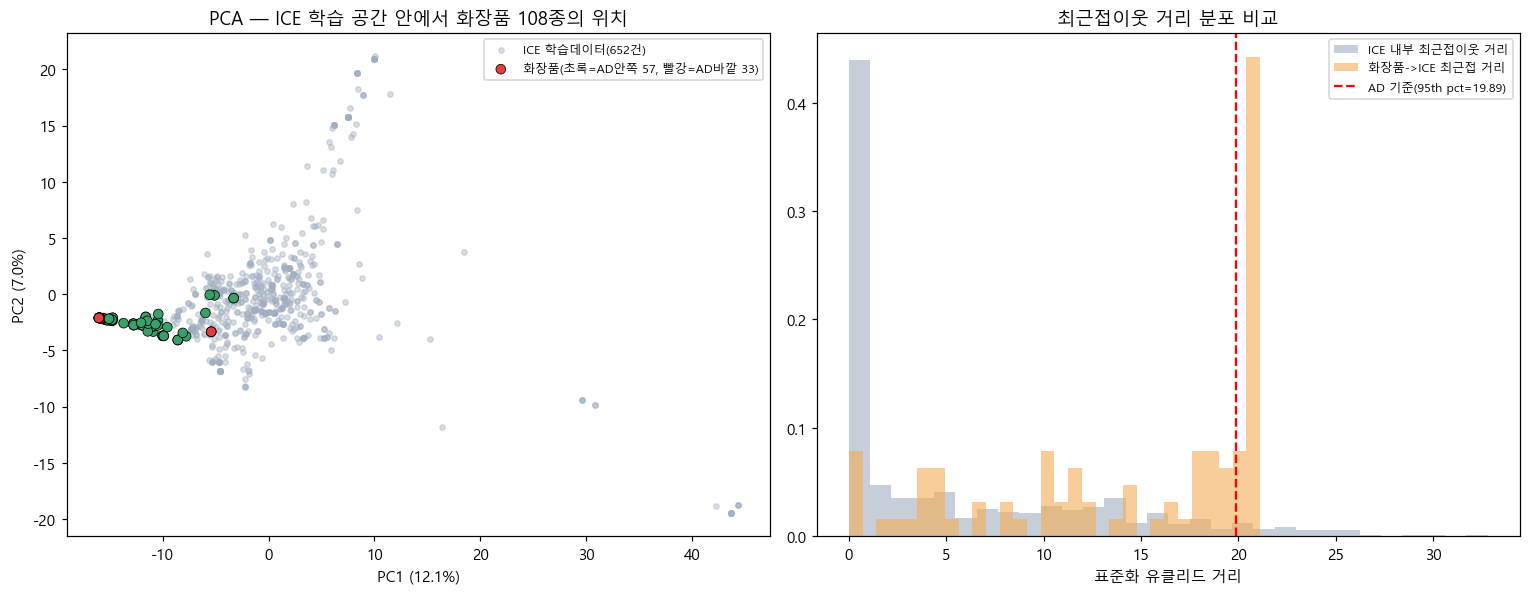

In [4]:
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=0).fit(X_ice_s)
ice_pca = pca.transform(X_ice_s)
cos_pca = pca.transform(X_cos_s)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(ice_pca[:, 0], ice_pca[:, 1], s=12, alpha=0.4, color="#a0aec0", label=f"ICE 학습데이터({len(ice_pca)}건)")
colors = np.where(in_ad, "#38a169", "#e53e3e")
axes[0].scatter(cos_pca[:, 0], cos_pca[:, 1], s=40, c=colors, edgecolor="black", linewidth=0.5,
               label=f"화장품(초록=AD안쪽 {in_ad.sum()}, 빨강=AD바깥 {(~in_ad).sum()})")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
axes[0].set_title("PCA — ICE 학습 공간 안에서 화장품 108종의 위치")
axes[0].legend(fontsize=8)

axes[1].hist(internal_nn_dist, bins=30, alpha=0.6, color="#a0aec0", label="ICE 내부 최근접이웃 거리", density=True)
axes[1].hist(cos_nn_dist, bins=30, alpha=0.6, color="#f6ad55", label="화장품->ICE 최근접 거리", density=True)
axes[1].axvline(threshold, color="red", linestyle="--", label=f"AD 기준(95th pct={threshold:.2f})")
axes[1].set_xlabel("표준화 유클리드 거리")
axes[1].set_title("최근접이웃 거리 분포 비교")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 4. AD 안쪽/바깥쪽 화장품 목록

In [5]:
ad_df = pd.DataFrame({"product": cos_df["product"], "nn_distance": cos_nn_dist, "in_ad": in_ad}).sort_values("nn_distance")
print("AD 안쪽(가장 가까운 상위 10개):")
print(ad_df[ad_df["in_ad"]].head(10).to_string(index=False))
print(f"\nAD 바깥쪽(가장 먼 상위 10개, 총 {(~ad_df['in_ad']).sum()}개 중):")
print(ad_df[~ad_df["in_ad"]].sort_values("nn_distance", ascending=False).head(10).to_string(index=False))

AD 안쪽(가장 가까운 상위 10개):
                                                 product  nn_distance  in_ad
                        Go Ready Sun Screen SPF 30 Spray     0.000000   True
                   SPF30 Plus Sunscreen Continuous Spray     0.000000   True
                                                sx toner     0.000000   True
                         ideal aerosol spray covers-over     0.554670   True
Water Based Aerosols Hair Mousses - NFPA Level 1 Aerosol     0.582453   True
                                 Pearlized Nail Polish 4     1.642277   True
                        PDC Skin Musk for Men Body Spray     2.802961   True
                            Broadway Nail Art (Top Coat)     3.109142   True
                                    Nail top coat MQ 520     3.911296   True
                           PDC Coconut Breeze Body Spray     4.121435   True

AD 바깥쪽(가장 먼 상위 10개, 총 33개 중):
                         product  nn_distance  in_ad
                     Bubble Bath    21.116611  

## 정리

- 화장품 타깃을 27종 → 108종으로 늘려서 AD를 재계산했다. 표본이 커져 결과가 이전처럼 집계 방식에
  따라 크게 흔들리지는 않는다(안정적인 단일 추정치 확보).
- 방법은 표준 QSAR 적용범위 판정법 중 하나인 최근접이웃 거리(distance to model) — ICE 학습데이터
  자체의 내부 산포(95th percentile)를 기준선으로 삼아 화장품이 그 안쪽인지 바깥쪽인지 판정했다.
- **주의**: 이 결과는 skin_rf 모델이 "구조적으로 화장품에 적용 가능한 범위인지"를 보여주는 것이지,
  실제 화장품 자극성 예측 성능을 검증한 것은 아니다(라벨이 없어 정확도 계산 불가) — 여전히
  "화장품 외부검증 수행하지 않음" 원칙은 유지된다.